# Do Indian active mutual funds beat index funds after costs?

Rolling 3- and 5-year returns of every open-ended Large Cap, Flexi Cap and Mid Cap fund
(growth option) since 2013, compared with a direct-plan index fund in the same category.
All numbers come from the SQL views built by `python -m src.pipeline all`; this notebook
only reads them.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from src.report import CATEGORIES, COLORS, beat_share_over_time, headline, query, view

FIG_DIR = pathlib.Path.cwd().parent / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": COLORS["grid"], "axes.labelcolor": COLORS["text_secondary"],
    "xtick.color": COLORS["text_secondary"], "ytick.color": COLORS["text_secondary"],
    "text.color": COLORS["text"], "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"], "grid.linewidth": 0.6, "legend.frameon": False,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
h = headline()

## 1. The data

In [2]:
schemes = view("schemes")
active = schemes[~schemes.is_benchmark]
print(f"{len(active)} active fund plans ({active.base_scheme_key.nunique()} funds) and 3 benchmark index funds")
print(f"NAV history {schemes.first_nav_date.min()} to {h.data_as_of}")
active.groupby(["category", "plan_type"]).size().unstack()

256 active fund plans (128 funds) and 3 benchmark index funds
NAV history 2013-01-01 to 2026-10-26


plan_type,direct,regular
category,,
Flexi Cap,47,47
Large Cap,41,41
Mid Cap,40,40


**Benchmarks** (`config/benchmarks.yaml`) are direct-plan index funds, so the comparison is
investable and already net of the index fund's own costs. The Nifty 500 and Midcap 150 index
funds only launched in September 2019, which limits Flexi Cap and Mid Cap to 3-year windows
ending from Sep 2022 and 5-year windows ending from Sep 2024.

In [3]:
query('''
    SELECT b.category, b.index_name, s.scheme_name, s.first_nav_date,
           MIN(r.end_date) FILTER (WHERE r.window_years = 5) AS first_5y_window_end
    FROM benchmarks b JOIN schemes s USING (scheme_code)
    JOIN rolling_returns r USING (scheme_code)
    GROUP BY 1, 2, 3, 4 ORDER BY s.first_nav_date
''')

,category,index_name,scheme_name,first_nav_date,first_5y_window_end
0,Large Cap,Nifty 50,UTI Nifty 50 Index Fund - Direct Plan - Growth,2013-01-02,2018-01-31
1,Flexi Cap,Nifty 500,Motilal Oswal Nifty 500 Index Fund - Direct Pl...,2019-09-11,2024-09-30
2,Mid Cap,Nifty Midcap 150,Motilal Oswal Nifty Midcap 150 Index Fund - Di...,2019-09-11,2024-09-30


### Data quality

* NAVs come from mfapi.in. A sample of ~7,900 NAVs from AMFI's own history files matched
  mfapi to within 0.01% in every case (check below, on every fourth quarterly snapshot).
* Zero/negative NAVs are dropped and logged; single-day moves above 20% are logged and kept.
* Schemes that were excluded or could not be paired are logged in `scheme_log`.

In [4]:
import glob, json
from src.ingest.amfi import parse
raw = pathlib.Path.cwd().parent / "data" / "raw"
codes = set(schemes.scheme_code)
amfi = pd.concat(parse(open(p, encoding="utf-8", errors="replace").read())
                 for p in sorted(glob.glob(str(raw / "amfi" / "history_*.txt")))[::4])
amfi = amfi[amfi.scheme_code.isin(codes)].assign(
    nav_date=lambda d: pd.to_datetime(d["date"], format="%d-%b-%Y").dt.date,
    amfi_nav=lambda d: pd.to_numeric(d["nav"], errors="coerce"))
mf = query("SELECT scheme_code, nav_date, nav::float8 AS mfapi_nav FROM nav_daily")
check = amfi.merge(mf, on=["scheme_code", "nav_date"], how="inner")
match = ((check.amfi_nav - check.mfapi_nav).abs() <= 1e-4 * check.amfi_nav).mean()
print(f"AMFI vs mfapi: {len(check):,} NAVs compared, {match:.2%} match within 0.01%")

AMFI vs mfapi: 7,900 NAVs compared, 100.00% match within 0.01%


In [5]:
flags = view("nav_flags")
log = view("scheme_log")
print("NAV flags:", flags.flag_type.value_counts().to_dict() or "none")
log.assign(issue=log.issue.str.split(":").str[0]).groupby("issue").size()

NAV flags: {'nonpositive_nav': 6}


issue
category_mismatch             4
legacy_share_class_dropped    2
not_growth_option             7
dtype: int64

## 2. Headline: share of active funds that beat the index fund

In [6]:
cs = view("category_summary")
five = cs[cs.window_years == 5].pivot(index="category", columns="plan_type", values="share_funds_beating")
five = five.loc[CATEGORIES + ["All"]]
print(f"Direct plans: {h.direct_share_beating_5y:.0%} of {h.direct_funds_5y} funds beat their index fund "
      f"in their median rolling 5-year window (median excess {h.direct_median_excess_5y:+.2%} a year).")
print(f"Regular plans: {h.regular_share_beating_5y:.0%} (median excess {h.regular_median_excess_5y:+.2%} a year).")
cs[cs.window_years.isin([3, 5])].set_index(["window_years", "plan_type", "category"])[
    ["n_funds", "share_funds_beating", "pooled_beat_rate", "median_fund_excess"]].sort_index()

Direct plans: 57% of 75 funds beat their index fund in their median rolling 5-year window (median excess +0.19% a year).
Regular plans: 29% (median excess -0.96% a year).


n_funds  share_funds_beating  \
window_years plan_type category                                  
3            direct    All             92                0.587   
                       Flexi Cap       31                0.581   
                       Large Cap       34                0.706   
                       Mid Cap         27                0.444   
             regular   All             92                0.435   
                       Flexi Cap       31                0.452   
                       Large Cap       34                0.500   
                       Mid Cap         27                0.333   
5            direct    All             75                0.573   
                       Flexi Cap       24                0.583   
                       Large Cap       30                0.633   
                       Mid Cap         21                0.476   
             regular   All             75                0.293   
                       Flexi Cap       24                0.333   
                       Large Cap       30                0.300   
                       Mid Cap         21                0.238   

                                  pooled_beat_rate  median_fund_excess  
window_years plan_type category                                         
3            direct    All                   0.580               0.010  
                       Flexi Cap             0.591               0.007  
                       Large Cap             0.623               0.012  
                       Mid Cap               0.438              -0.006  
             regular   All                   0.436              -0.005  
                       Flexi Cap             0.439              -0.006  
                       Large Cap             0.471              -0.001  
                       Mid Cap               0.326              -0.024  
5            direct    All                   0.563               0.002  
                       Flexi Cap             0.562               0.002  
                       Large Cap             0.586               0.007  
                       Mid Cap               0.454              -0.003  
             regular   All                   0.368              -0.010  
                       Flexi Cap             0.383              -0.010  
                       Large Cap             0.380              -0.005  
                       Mid Cap               0.293              -0.020

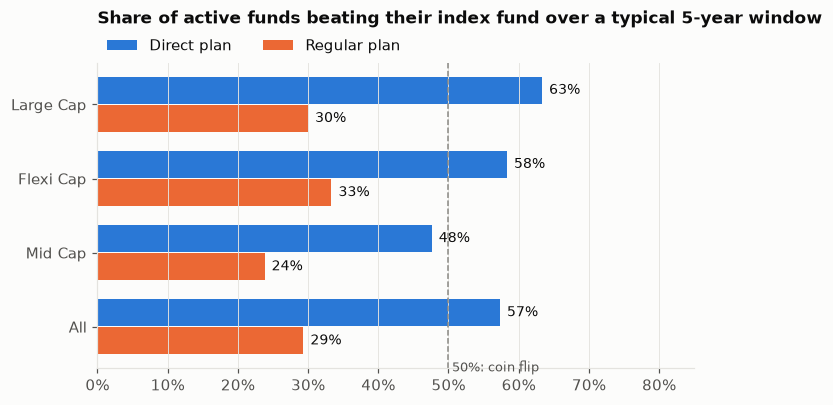

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = range(len(five))
bh = 0.36
for i, (plan, offset) in enumerate([("direct", -bh / 2 - 0.01), ("regular", bh / 2 + 0.01)]):
    vals = five[plan].values
    ax.barh([v + offset for v in y], vals, height=bh, color=COLORS[plan], label=f"{plan.title()} plan")
    for yy, v in zip(y, vals):
        ax.text(v + 0.01, yy + offset, f"{v:.0%}", va="center", fontsize=9, color=COLORS["text"])
ax.axvline(0.5, color=COLORS["index"], lw=1, ls="--")
ax.text(0.505, len(five) - 0.45, "50%: coin flip", color=COLORS["text_secondary"], fontsize=8.5, va="center")
ax.set_yticks(list(y), five.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(0, 0.85)
ax.grid(axis="y", visible=False)
ax.set_title("Share of active funds beating their index fund over a typical 5-year window", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
fig.savefig(FIG_DIR / "beat_share_by_category.png")

A fund "beats" when its **median** rolling 5-year CAGR, across all its monthly windows, is
above the index fund's over the same windows. In direct plans this is barely better than a coin
flip, and Mid Cap funds do worse than one. The regular plan's commission turns it into a losing
bet in every category.

## 3. The answer depends on when you look

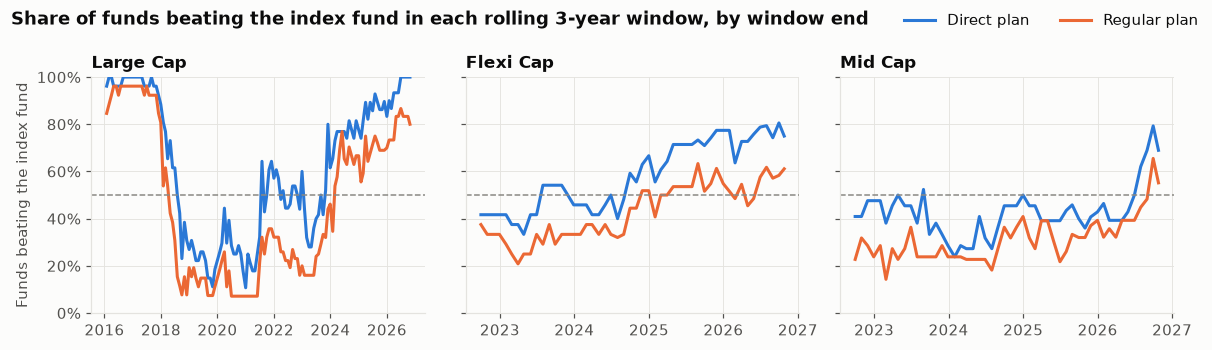

In [8]:
t = beat_share_over_time(3)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, cat in zip(axes, CATEGORIES):
    for plan in ("direct", "regular"):
        s = t[(t.category == cat) & (t.plan_type == plan)]
        ax.plot(pd.to_datetime(s.end_date), s.share_beating, color=COLORS[plan], lw=2, label=f"{plan.title()} plan")
    ax.axhline(0.5, color=COLORS["index"], lw=1, ls="--")
    ax.set_title(cat)
    ax.yaxis.set_major_formatter(pct)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
axes[0].set_ylabel("Funds beating the index fund")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2)
fig.suptitle("Share of funds beating the index fund in each rolling 3-year window, by window end", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "beat_share_over_time.png")

In [9]:
t5 = beat_share_over_time(5)
lc = t5[(t5.category == "Large Cap") & (t5.plan_type == "direct")]
lc.assign(year=pd.to_datetime(lc.end_date).dt.year).groupby("year").share_beating.agg(["min", "max"])

,min,max
year,,
2018,0.885,0.962
2019,0.577,0.885
2020,0.231,0.692
2021,0.148,0.370
2022,0.120,0.333
2023,0.250,0.652
2024,0.652,0.833
2025,0.583,0.731
2026,0.731,0.889


For Large Cap, the share of direct plans beating the Nifty 50 index fund over 5 years has
ranged from 12% (windows ending Apr 2022) to 96% (Feb 2018) depending on the window. Active large-cap funds can hold
mid caps, so they look good when mid caps outperform the Nifty 50 and bad when they don't.
That is a style tilt, not necessarily skill, and it doesn't persist.

## 4. Fund-level spread

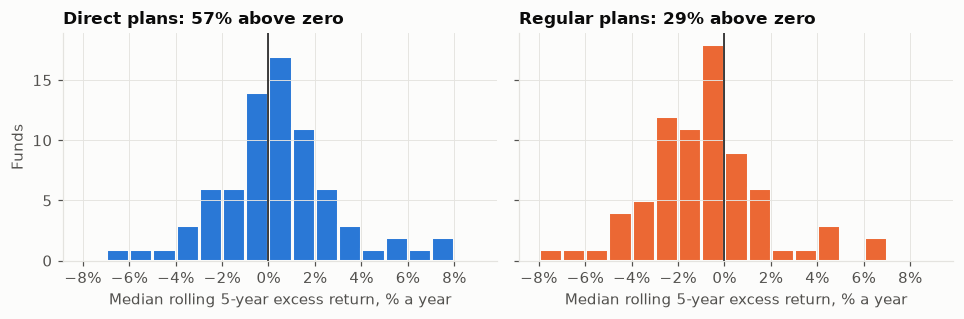

In [10]:
fb = view("fund_beat_rates")
fb5 = fb[(fb.window_years == 5) & (fb.n_windows >= 12)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True, sharex=True)
bins = [x / 100 for x in range(-8, 10)]
for ax, plan in zip(axes, ("direct", "regular")):
    s = fb5[fb5.plan_type == plan].median_excess
    ax.hist(s, bins=bins, color=COLORS[plan], edgecolor=COLORS["surface"], linewidth=2)
    ax.axvline(0, color=COLORS["text"], lw=1)
    ax.set_title(f"{plan.title()} plans: {(s > 0).mean():.0%} above zero")
    ax.xaxis.set_major_locator(mtick.MultipleLocator(0.02))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("Median rolling 5-year excess return, % a year")
axes[0].set_ylabel("Funds")
fig.tight_layout()
fig.savefig(FIG_DIR / "fund_excess_distribution.png")

## 5. What the regular plan costs

In [11]:
gap = view("direct_regular_gap")
print(f"{h.n_pairs} direct/regular pairs; median gap {h.median_annual_gap:.2%} a year")
print(f"{h.n_pairs_with_sip} pairs with 10 full years: on a Rs 10,000/month SIP (Rs {h.sip_invested:,.0f} invested), "
      f"the direct plan ended Rs {h.median_sip_rupee_gap:,.0f} ahead at the median")
gap.groupby("category")[["annual_gap", "sip_rupee_gap"]].median()

105 direct/regular pairs; median gap 1.32% a year
57 pairs with 10 full years: on a Rs 10,000/month SIP (Rs 1,200,000 invested), the direct plan ended Rs 131,428 ahead at the median


,annual_gap,sip_rupee_gap
category,,
Flexi Cap,0.014,120601.020
Large Cap,0.013,122972.515
Mid Cap,0.014,152417.050


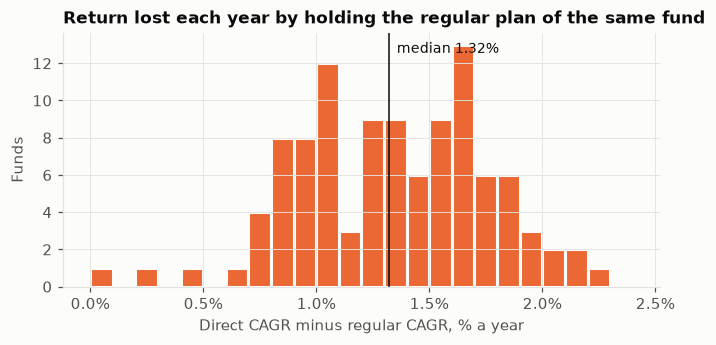

In [12]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(gap.annual_gap, bins=[x / 1000 for x in range(0, 25)], color=COLORS["regular"],
        edgecolor=COLORS["surface"], linewidth=2)
ax.axvline(h.median_annual_gap, color=COLORS["text"], lw=1)
ax.text(h.median_annual_gap, ax.get_ylim()[1] * 0.92, f"  median {h.median_annual_gap:.2%}", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.set_xlabel("Direct CAGR minus regular CAGR, % a year")
ax.set_ylabel("Funds")
ax.set_title("Return lost each year by holding the regular plan of the same fund")
fig.savefig(FIG_DIR / "direct_regular_gap.png")

## 6. Risk-adjusted view (trailing 5 years)

In [13]:
rm = query('''
    SELECT CASE WHEN s.is_benchmark THEN 'index fund' ELSE s.plan_type END AS plan, s.category,
           r.cagr, r.volatility, r.sharpe, r.sortino, r.max_drawdown
    FROM risk_metrics r JOIN schemes s USING (scheme_code)
''')
rm.groupby("plan")[["cagr", "volatility", "sharpe", "sortino", "max_drawdown"]].median()

,cagr,volatility,sharpe,sortino,max_drawdown
plan,,,,,
direct,0.089,0.144,0.230,0.309,-0.197
index fund,0.076,0.145,0.144,0.193,-0.186
regular,0.077,0.144,0.149,0.201,-0.201


Risk-free rate is 6.5% (configurable in `config/settings.yaml`).

## 7. Survivorship

In [14]:
view("survivorship").query("plan_type == 'direct'").set_index("category")

,plan_type,window_start,window_end,schemes_at_start,schemes_at_end,closed_or_merged,launched_since,launched_and_closed
category,,,,,,,,
Mid Cap,direct,2016-10-26,2026-10-26,20,34,3,20,3
Large Cap,direct,2016-10-26,2026-10-26,27,35,5,14,1
Flexi Cap,direct,2016-10-26,2026-10-26,19,46,1,28,0
All,direct,2016-10-26,2026-10-26,66,115,9,62,4


In [15]:
unmapped = pd.read_csv(raw / "universe_unmapped_equity.csv")
old = unmapped[unmapped.category == "Growth"]
print(f"{len(old)} plans carry only the pre-2018 'Growth' label and can't be placed in a current category; "
      f"{(pd.to_datetime(old.last_seen) >= '2016-10-01').sum()} of them were still alive in Oct 2016.")

374 plans carry only the pre-2018 'Growth' label and can't be placed in a current category; 139 of them were still alive in Oct 2016.


Funds that closed or merged *after* SEBI's 2018 recategorisation are included (AMFI lists them
under their last category), so their windows count until they disappear. Funds that closed
before or during the recategorisation can't be placed in Large/Flexi/Mid Cap and are missing.
Funds tend to be merged away after poor performance, so these results, if anything, flatter
active funds.

## 8. Limitations

1. **Short benchmark history for Flexi Cap and Mid Cap.** Index funds on the Nifty 500 and
   Midcap 150 start in Sep 2019, so their 5-year windows all end between Sep 2024 and Oct 2026
   and overlap heavily: in effect one market cycle.
2. **Benchmark fit.** The Nifty 50 is narrower than the 100 stocks Large Cap funds must mostly
   hold; part of their "excess" is a mid-cap tilt. A Nifty 100 index fund would be a tighter
   comparison but has a shorter history.
3. **Survivorship** is reduced but not removed (section 7).
4. **Categories are as of today.** A fund recategorised in 2018 is analysed under its current
   category for its whole history.
5. **Taxes and exit loads** are ignored; they apply to both sides of the comparison.